# Ejercicio Regression Tree
Son datos de temperaturas tomados de la ciudad de Seattle. El objetivo es intentar predecir lo mejor posible la máxima temperatura (columna `actual`) que alcanzaremos al día siguiente. Para ello contaremos con temperaturas de los dos días anteriores, históricos de máximas temperaturas y un amigo bastante chapas que te da su predicción del tiempo cada día.

**Resumen de datos**:
* year: 2016 for all data points
* month: number for month of the year
* day: number for day of the year
* week: day of the week as a character string
* temp_2: max temperature 2 days prior
* temp_1: max temperature 1 day prior
* average: historical average max temperature
* actual: max temperature measurement
* friend: your friend’s prediction, a random number between 20 below the average and 20 above the average


### 1. Importa el csv "temps.csv"

In [19]:
import pandas as pd

df = pd.read_csv('data/temps.csv')
df.head()

,year,month,day,week,temp_2,temp_1,average,actual,friend
0,2016,1,1,Fri,45,45,45.6,45,29
1,2016,1,2,Sat,44,45,45.7,44,61
2,2016,1,3,Sun,45,44,45.8,41,56
3,2016,1,4,Mon,44,41,45.9,40,53
4,2016,1,5,Tues,41,40,46.0,44,41


### 2. Realiza un análisis exploratorio junto con un Feature Engineering

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 348 entries, 0 to 347
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   year     348 non-null    int64  
 1   month    348 non-null    int64  
 2   day      348 non-null    int64  
 3   week     348 non-null    object 
 4   temp_2   348 non-null    int64  
 5   temp_1   348 non-null    int64  
 6   average  348 non-null    float64
 7   actual   348 non-null    int64  
 8   friend   348 non-null    int64  
dtypes: float64(1), int64(7), object(1)
memory usage: 24.6+ KB


In [21]:
df.describe() #todos los registros corresponden a 2016

,year,month,day,temp_2,temp_1,average,actual,friend
count,348.0,348.000000,348.000000,348.000000,348.000000,348.000000,348.000000,348.000000
mean,2016.0,6.477011,15.514368,62.652299,62.701149,59.760632,62.543103,60.034483
std,0.0,3.498380,8.772982,12.165398,12.120542,10.527306,11.794146,15.626179
min,2016.0,1.000000,1.000000,35.000000,35.000000,45.100000,35.000000,28.000000
25%,2016.0,3.000000,8.000000,54.000000,54.000000,49.975000,54.000000,47.750000
50%,2016.0,6.000000,15.000000,62.500000,62.500000,58.200000,62.500000,60.000000
75%,2016.0,10.000000,23.000000,71.000000,71.000000,69.025000,71.000000,71.000000
max,2016.0,12.000000,31.000000,117.000000,117.000000,77.400000,92.000000,95.000000


     year  month  day  week  temp_2  temp_1  average  actual  friend
286  2016     10   31   Mon      65     117     54.8      59      62
287  2016     11    1  Tues     117      59     54.5      57      61


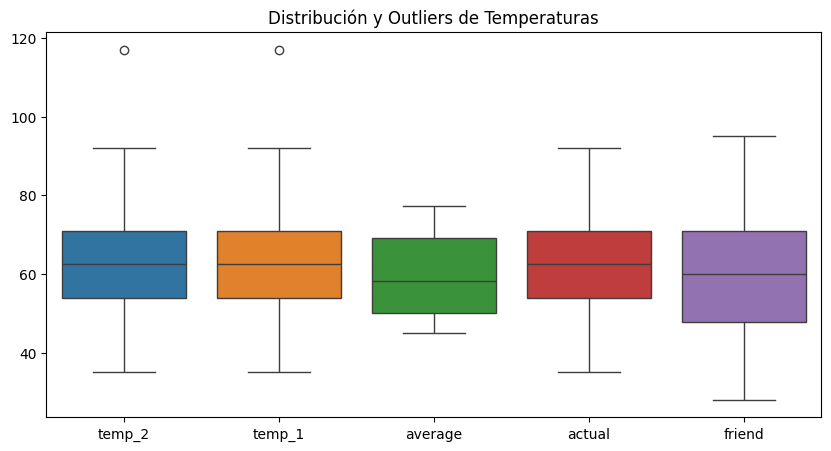

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Revisar las filas con temperaturas extremas (> 100°F)
print(df[(df['temp_1'] > 100) | (df['temp_2'] > 100)])

# 2. Boxplots para detectar outliers visualmente
cols_num = ['temp_2', 'temp_1', 'average', 'actual', 'friend']
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[cols_num])
plt.title('Distribución y Outliers de Temperaturas')
plt.show()

In [23]:
df_clean = df.copy()
df_clean.loc[df_clean['temp_1'] == 117, 'temp_1'] = df_clean['average']
df_clean.loc[df_clean['temp_2'] == 117, 'temp_2'] = df_clean['average']

C:\Users\laras\AppData\Local\Temp\ipykernel_15612\83068852.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[54.8]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_clean.loc[df_clean['temp_1'] == 117, 'temp_1'] = df_clean['average']
C:\Users\laras\AppData\Local\Temp\ipykernel_15612\83068852.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[54.5]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_clean.loc[df_clean['temp_2'] == 117, 'temp_2'] = df_clean['average']


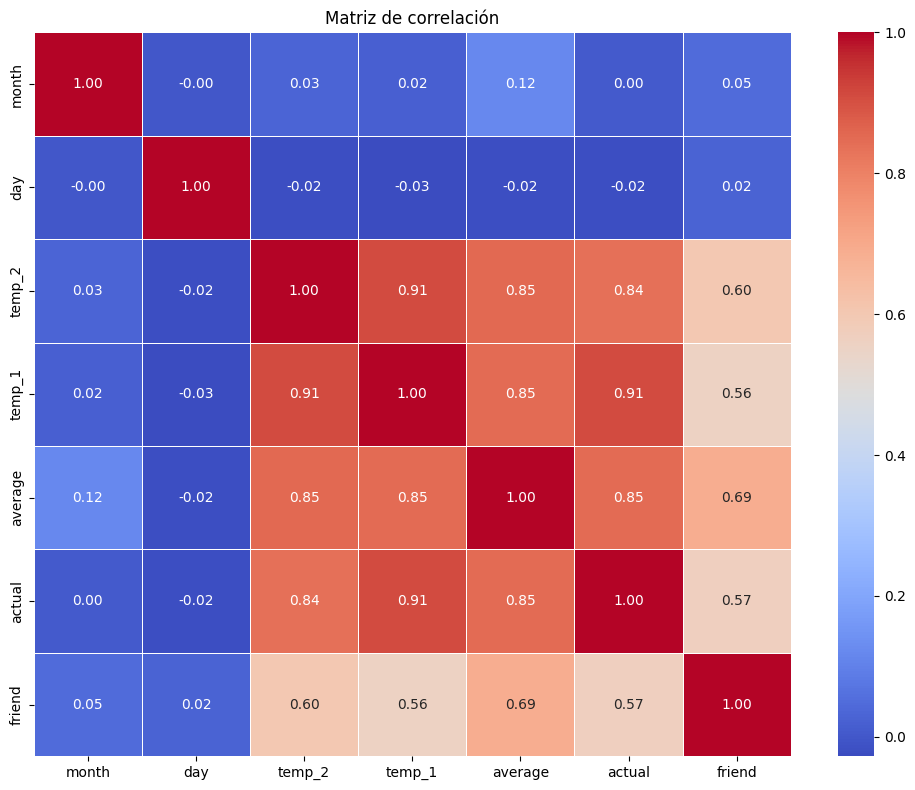

In [24]:
df_clean = df_clean.drop(columns=['year'])

corr = df_clean.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

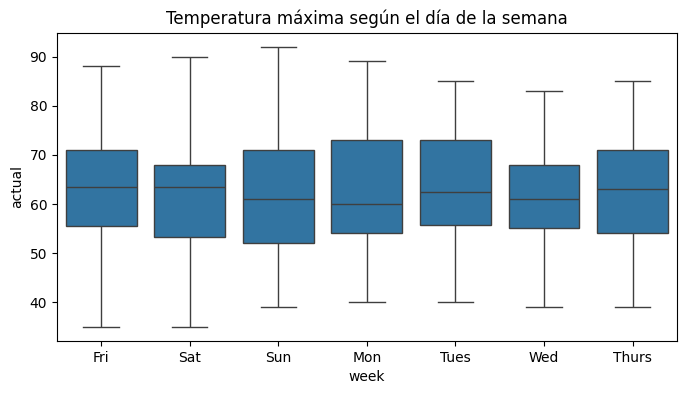

In [25]:
plt.figure(figsize=(8, 4))
sns.boxplot(x='week', y='actual', data=df)
plt.title('Temperatura máxima según el día de la semana')
plt.show()

In [26]:
# One-Hot Encoding para 'week'
df_clean = pd.get_dummies(df_clean, columns=['week'], drop_first=True, dtype=int)
df_clean.head()

,month,day,temp_2,temp_1,average,actual,friend,week_Mon,week_Sat,week_Sun,week_Thurs,week_Tues,week_Wed
0,1,1,45.0,45.0,45.6,45,29,0,0,0,0,0,0
1,1,2,44.0,45.0,45.7,44,61,0,1,0,0,0,0
2,1,3,45.0,44.0,45.8,41,56,0,0,1,0,0,0
3,1,4,44.0,41.0,45.9,40,53,1,0,0,0,0,0
4,1,5,41.0,40.0,46.0,44,41,0,0,0,0,1,0


### 3. Selecciona variables y divide en train y test

In [27]:
from sklearn.model_selection import train_test_split

# 1. Seleccionar variables predictoras (X) y objetivo (y)
X = df_clean.drop(columns=['actual'])
y = df_clean['actual']

# 2. Dividir en train y test (80% entrenamiento, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Comprobar tamaños
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

X_train: (278, 12), X_test: (70, 12)
y_train: (278,), y_test: (70,)


### 4. Entrena el modelo


In [28]:
from sklearn.tree import DecisionTreeRegressor

# 1. Instanciar el modelo (random_state para reproducibilidad)
tree_reg = DecisionTreeRegressor(random_state=42)

# 2. Entrenar el modelo
tree_reg.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

### 5. Evaluación de tu modelo
Calcula el coeficiente de determinación. 

Calcula el MAE, MAPE, MSE y RMSE.

In [29]:
import numpy as np
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error
)

# 1. Predecir sobre test (y sobre train para comparar overfitting)
y_pred = tree_reg.predict(X_test)
y_pred_train = tree_reg.predict(X_train)

# 2. Calcular métricas en test
r2_train = r2_score(y_train, y_pred_train)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

# 3. Mostrar resultados
print(f"R2 (Train): {r2_train:.4f}")
print(f"R2 (Test):  {r2:.4f}")
print(f"MAE:        {mae:.4f} °F")
print(f"MAPE:       {mape * 100:.2f} %")
print(f"MSE:        {mse:.4f}")
print(f"RMSE:       {rmse:.4f} °F")


R2 (Train): 1.0000
R2 (Test):  0.7802
MAE:        3.9571 °F
MAPE:       6.44 %
MSE:        30.7286
RMSE:       5.5433 °F


### 6. Representa el árbol de decisión

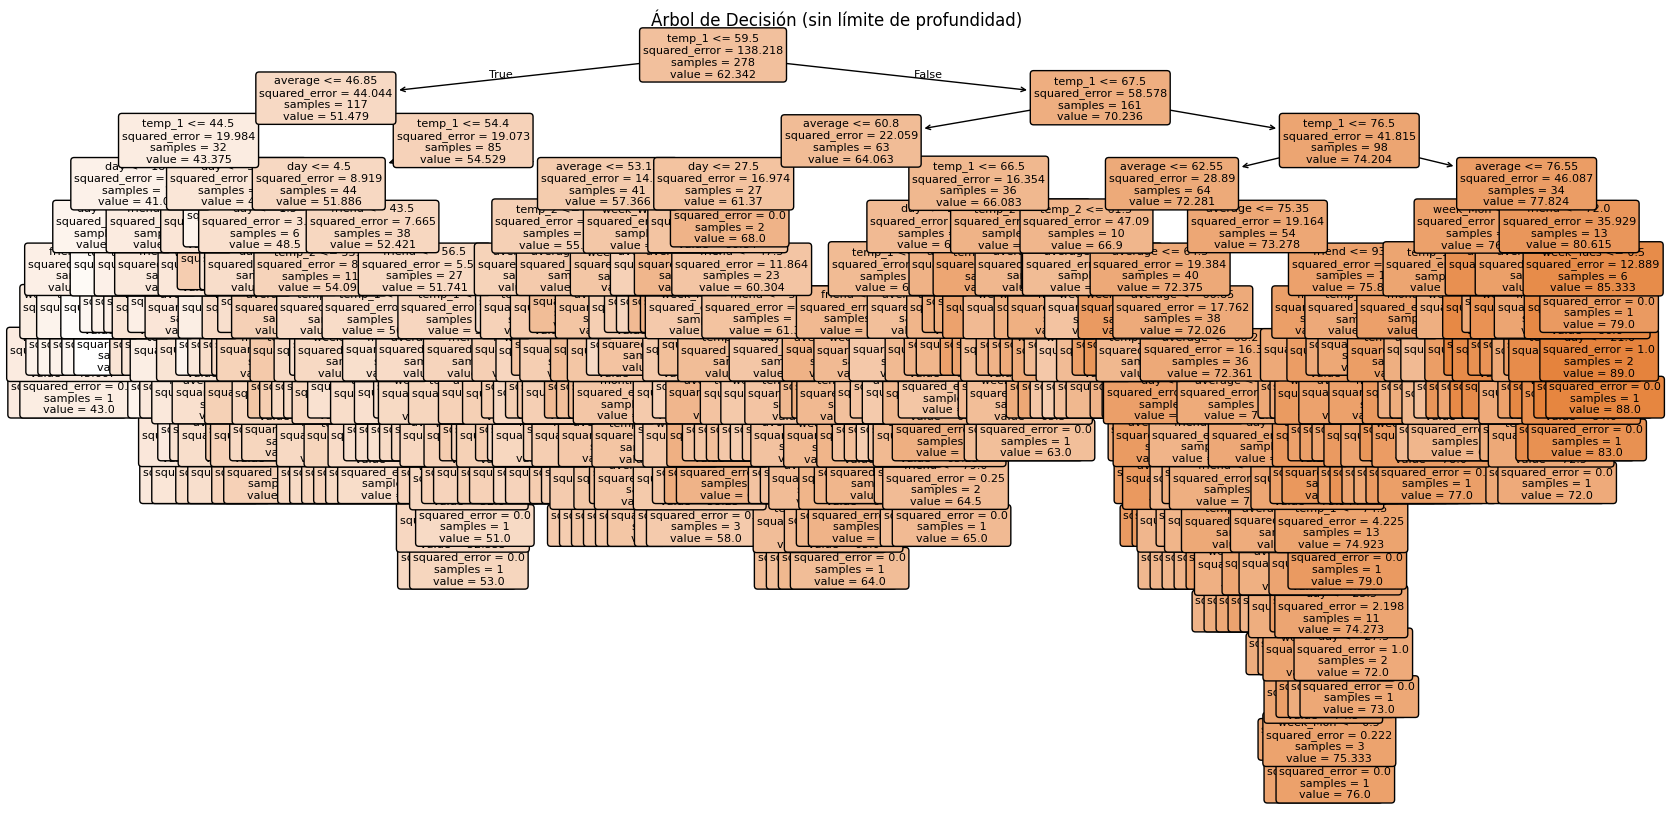

In [30]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    tree_reg,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Árbol de Decisión (sin límite de profundidad)")
plt.show()

### 7. Modifica el max_depth a 3 y vuelve a entrenarlo

In [31]:
# 1. Instanciar el modelo con max_depth=3
tree_reg_3 = DecisionTreeRegressor(max_depth=3, random_state=42)

# 2. Entrenar el modelo
tree_reg_3.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

### 8. Vuelve a evaluar tu modelo

In [32]:
# 1. Predecir sobre test y train con el nuevo modelo
y_pred_3 = tree_reg_3.predict(X_test)
y_pred_train_3 = tree_reg_3.predict(X_train)

# 2. Calcular métricas
r2_train_3 = r2_score(y_train, y_pred_train_3)
r2_3 = r2_score(y_test, y_pred_3)
mae_3 = mean_absolute_error(y_test, y_pred_3)
mape_3 = mean_absolute_percentage_error(y_test, y_pred_3)
mse_3 = mean_squared_error(y_test, y_pred_3)
rmse_3 = np.sqrt(mse_3)

# 3. Mostrar resultados
print(f"R2 (Train): {r2_train_3:.4f}")
print(f"R2 (Test):  {r2_3:.4f}")
print(f"MAE:        {mae_3:.4f} °F")
print(f"MAPE:       {mape_3 * 100:.2f} %")
print(f"MSE:        {mse_3:.4f}")
print(f"RMSE:       {rmse_3:.4f} °F")

R2 (Train): 0.8467
R2 (Test):  0.8224
MAE:        4.0662 °F
MAPE:       6.48 %
MSE:        24.8376
RMSE:       4.9837 °F


### 9. Vuelve a representar su árbol

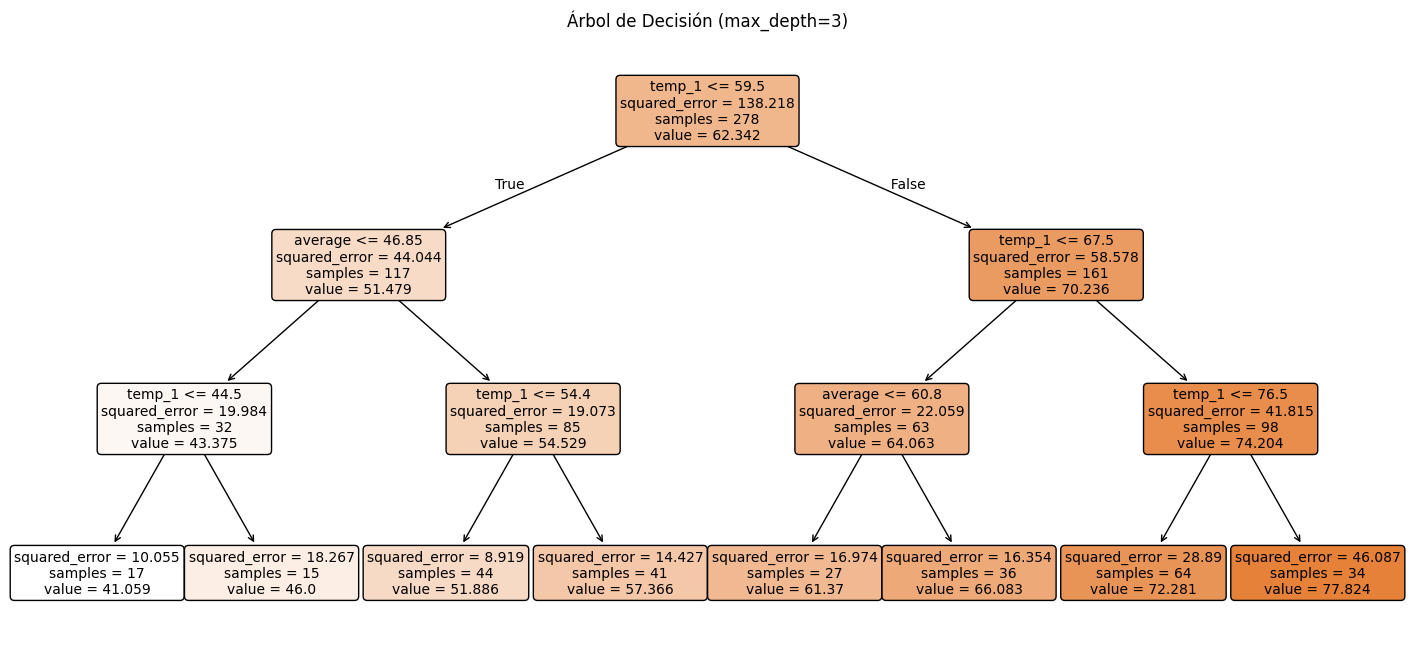

In [33]:
plt.figure(figsize=(18, 8))
plot_tree(
    tree_reg_3,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Árbol de Decisión (max_depth=3)")
plt.show()

### 10. Utiliza un grid search con cross validation para hiperparametrizar tu modelo

In [ ]:
from sklearn.model_selection import GridSearchCV

# 1. Definir la rejilla de hiperparámetros a probar
param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8, 10]
}

#Al tener 8 valores de max_depth, 4 de min_samples_split y 5 de min_samples_leaf, Grid Search genera 8 * 4 * 5 = 160 combinaciones distintas.

# 2. Configurar GridSearchCV (usando R2 como métrica de evaluación)
grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42), #El modelo base que se va a clonar y entrenar en cada prueba (DecisionTreeRegressor(random_state=42)
    param_grid=param_grid, 
    cv=5, #En total, grid_search.fit(X_train, y_train) entrena $160 { combinaciones} * 5{ pliegues} = 800{ árboles}$.
    scoring='r2', #El criterio para decidir qué combinación gana (en regresión también se usa mucho 'neg_mean_squared_error' o 'neg_mean_absolute_error').
    n_jobs=-1 #Usa todos los núcleos de tu procesador en paralelo para entrenar los 800 árboles mucho más rápido.
)

# 3. Entrenar sobre los datos de train
grid_search.fit(X_train, y_train)

# 4. Ver los mejores hiperparámetros y el mejor score en CV
print("Mejores parámetros:", grid_search.best_params_)
print(f"Mejor R2 (CV):      {grid_search.best_score_:.4f}")

# 5. Guardar el mejor modelo y evaluarlo en test
best_tree = grid_search.best_estimator_ #Por defecto (refit=True), una vez encontrada la combinación ganadora, Scikit-Learn vuelve a entrenar un último árbol con todo X_train usando esos mejores hiperparámetros y lo guarda aquí.
y_pred_best = best_tree.predict(X_test)

print(f"\nR2 (Test):   {r2_score(y_test, y_pred_best):.4f}")
print(f"MAE (Test):  {mean_absolute_error(y_test, y_pred_best):.4f} °F")
print(f"RMSE (Test): {np.sqrt(mean_squared_error(y_test, y_pred_best)):.4f} °F")

Mejores parámetros: {'max_depth': 5, 'min_samples_leaf': 10, 'min_samples_split': 2}
Mejor R2 (CV):      0.8012

R2 (Test):   0.8129
MAE (Test):  3.9888 °F
RMSE (Test): 5.1153 °F


Como no sabemos de antemano si el árbol funciona mejor con profundidad 3, 4 o 5, ni cuántas muestras mínimas debe tener cada hoja, usamos Grid Search para probar todas las combinaciones de forma sistemática.

max_depth: Profundidad máxima del árbol. Cuanto menor es, más simple es el modelo y menos sobreajusta.

min_samples_split: Número mínimo de datos que debe tener un nodo para poder dividirse en dos. Si pones 10, un nodo con 9 filas ya no se divide.

min_samples_leaf: Número mínimo de datos que debe quedar en cada hoja final. Evita crear hojas con 1 solo dato (que suelen ser ruido o outliers).

### 11. Obten el `feature_importances` de cada variable en el último modelo

      Variable  Importancia
3       temp_1     0.873435
4      average     0.124375
1          day     0.002190
0        month     0.000000
2       temp_2     0.000000
5       friend     0.000000
6     week_Mon     0.000000
7     week_Sat     0.000000
8     week_Sun     0.000000
9   week_Thurs     0.000000
10   week_Tues     0.000000
11    week_Wed     0.000000


C:\Users\laras\AppData\Local\Temp\ipykernel_15612\3140870722.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Variable', data=importancias, palette='viridis')


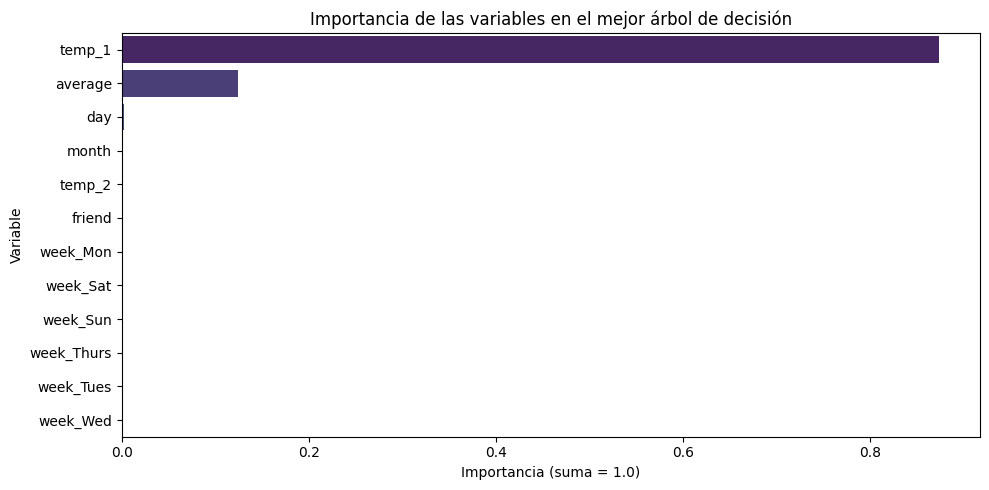

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Crear DataFrame con la importancia de cada variable
importancias = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': best_tree.feature_importances_
}).sort_values(by='Importancia', ascending=False)

# Mostrar tabla ordenada
print(importancias)

# 2. Gráfico de barras
plt.figure(figsize=(10, 5))
sns.barplot(x='Importancia', y='Variable', data=importancias, palette='viridis')
plt.title('Importancia de las variables en el mejor árbol de decisión')
plt.xlabel('Importancia (suma = 1.0)')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

### 12. Construye un nuevo modelo `DecisionTreeClassifier` que te clasifique cuando en un día va a hacer una temperatura mayor a 15ºC (59ºF). ¡Deberá tratarse como un problema de **clasificación**! Utiliza un grid search con cross validation y evalúa el mejor modelo.

Distribución de clases (0: <=59°F, 1: >59°F):
actual
1    0.586
0    0.414
Name: proportion, dtype: float64

Mejores parámetros: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 8, 'min_samples_split': 2}
Mejor Accuracy (CV): 0.9209

Accuracy (Test): 0.9143

Reporte de Clasificación:
              precision    recall  f1-score   support

 <= 59°F (0)       1.00      0.79      0.88        29
  > 59°F (1)       0.87      1.00      0.93        41

    accuracy                           0.91        70
   macro avg       0.94      0.90      0.91        70
weighted avg       0.93      0.91      0.91        70



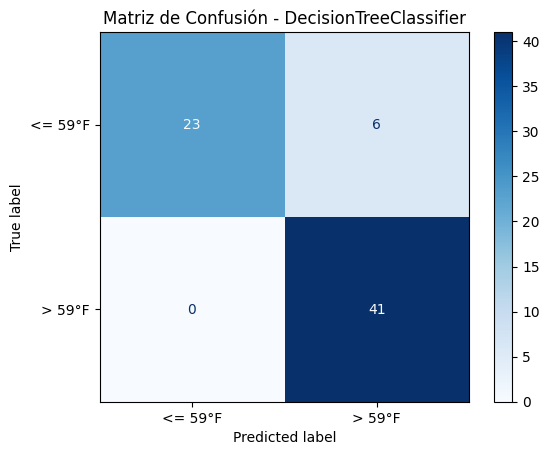

In [36]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# 1. Crear la nueva variable objetivo binaria (1 si > 59°F, 0 si <= 59°F)
X_clf = df_clean.drop(columns=['actual'])
y_clf = (df_clean['actual'] > 59).astype(int)

# Comprobar el balance de clases
print("Distribución de clases (0: <=59°F, 1: >59°F):")
print(y_clf.value_counts(normalize=True).round(3))

# 2. Dividir en train y test (stratify mantiene la misma proporción de 0 y 1 en ambos)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

# 3. Configurar GridSearchCV para DecisionTreeClassifier
param_grid_clf = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 3, 4, 5, 6, 8, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8]
}

grid_clf = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_clf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# 4. Entrenar GridSearchCV
grid_clf.fit(X_train_c, y_train_c)

print("\nMejores parámetros:", grid_clf.best_params_)
print(f"Mejor Accuracy (CV): {grid_clf.best_score_:.4f}")

# 5. Evaluar el mejor modelo en test
best_clf = grid_clf.best_estimator_
y_pred_c = best_clf.predict(X_test_c)

print(f"\nAccuracy (Test): {accuracy_score(y_test_c, y_pred_c):.4f}\n")
print("Reporte de Clasificación:")
print(classification_report(y_test_c, y_pred_c, target_names=['<= 59°F (0)', '> 59°F (1)']))

# 6. Matriz de confusión
cm = confusion_matrix(y_test_c, y_pred_c)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['<= 59°F', '> 59°F'])
disp.plot(cmap='Blues')
plt.title("Matriz de Confusión - DecisionTreeClassifier")
plt.show()